# RAG Assignment: Baseline vs. Re-Ranking
**Document:** ICC Men's T20 World Cup 2026 Playing Conditions (single PDF, ~106 pages)

**Pipeline 1 (baseline):** Bi-Encoder (`BAAI/bge-small-en-v1.5`) → FAISS inner-product index → Top 10 → Top 3 → LLM → **Answer 1**
**Pipeline 2 (re-ranking):** the *same* Top 10 → Cross-Encoder (`cross-encoder/ms-marco-MiniLM-L-6-v2`) → Top 3 → LLM (identical prompt) → **Answer 2**

**LLM:** Gemini (`gemini-3.1-flash-lite`), temperature 0.

**Notebook map:** 1 Setup · 2 Load PDF · 3 Models · 4 Chunking (with experiment) · 5 Index · 6 Pipelines · 6b Failure mining (LLM-generated questions) · 7 Stress-test screening · 8 Answer 1 vs Answer 2 for every stress test · 9 Rank-shift detail · 10 Latency · 11 Scaling

## 1. Setup

In [1]:
!pip -q install pymupdf sentence-transformers faiss-cpu google-genai matplotlib pandas scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 38.8 MB/s eta 0:00:00


In [2]:
import re, time, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, faiss, pymupdf, torch
from IPython.display import display
from google.colab import files, userdata
from google import genai
from google.genai import types
from sentence_transformers import SentenceTransformer, CrossEncoder

# API key is stored in Colab Secrets (name: GEMINI_API_KEY), never written in the notebook
client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'), http_options=types.HttpOptions(timeout=30000))
MODEL = 'gemini-3.1-flash-lite'
print(client.models.generate_content(model=MODEL, contents='Reply with the single word: ready').text)

ready


## 2. Load the PDF
Text is extracted with PyMuPDF. Two cleaning steps, both so that every chunk contains rule text only: (1) the running page header ("ICC Men's T20 World Cup 2026 | Playing Conditions" plus page number) repeats on every page, so it is removed; (2) the cover, preamble and table of contents are cut, because the contents page repeats every law title and would act as a distractor that matches queries without answering them.

In [3]:
if not glob.glob('*.pdf'): files.upload()
doc = pymupdf.open(glob.glob('*.pdf')[0])
raw = ' '.join(p.get_text() for p in doc)

# remove repeated page headers (optional page number before them); whitespace-tolerant
hdr = r"(?:\d+\s*)?(?:ICC Men.s T20 World Cup 2026\s*\|\s*Playing Conditions|Playing Conditions\s*\|\s*ICC Men.s T20 World Cup 2026)"
text = re.sub(hdr, " ", raw)

# drop the cover, preamble and table of contents: the rules start at "1 THE PLAYERS / 1.1 Number of players"
m = re.search(r"1\s+THE PLAYERS\s+1\.1\s+Number of players", text)
print('Rules body found:', bool(m))
if m: text = text[m.start():]
words = text.split()
print(f'Pages: {len(doc)} | Words before cleaning: {len(raw.split()):,} | after: {len(words):,}')
print('Headers left in text:', len(re.findall(r"Playing Conditions\s*\|\s*ICC Men|World Cup 2026\s*\|\s*Playing Conditions", text)))
print(text[:500])

Saving ICC_T20_WC_RuleBook.pdf to ICC_T20_WC_RuleBook.pdf
Rules body found: True
Pages: 106 | Words before cleaning: 48,122 | after: 46,614
Headers left in text: 0
1	
THE PLAYERS
1.1	
Number of players
A match is played between two sides, each of eleven players, one of whom shall be captain.
1.2	
Nomination and replacement of players
1.2.1	
Each captain shall nominate 11 players plus a maximum of 4 substitute fielders in 
writing on the team sheet provided by the ICC. Other than set out in clause 1.2.7, 
no player (member of the playing eleven) may be changed after the nomination and 
prior to the start of play without the consent of the opposing captain. 


## 3. Load the two models
`bge-small` is the Bi-Encoder (retrieval). `ms-marco-MiniLM-L-6-v2` is the Cross-Encoder (re-ranking).

In [4]:
bi = SentenceTransformer('BAAI/bge-small-en-v1.5')
ce = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')
tok = ce.tokenizer   # used only to measure chunk length in tokens
print('Models loaded | device:', 'GPU' if torch.cuda.is_available() else 'CPU')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Models loaded | device: CPU


## 4. Chunking
**Decision:** fixed word windows with overlap. **Why a size experiment:** the Cross-Encoder reads (query + chunk) together and accepts at most 512 tokens, so chunks must fit with room left for the query. Overlap (30 words) stops a rule being cut in half at a boundary.

 chunk_words  n_chunks  avg_tokens  max_tokens  pct_too_long
         100       666       132.0         291           0.0
         150       389       197.0         409           0.0
         200       274       263.3         482           0.4
         300       173       393.8         658           1.7
         400       126       526.4         902          96.8


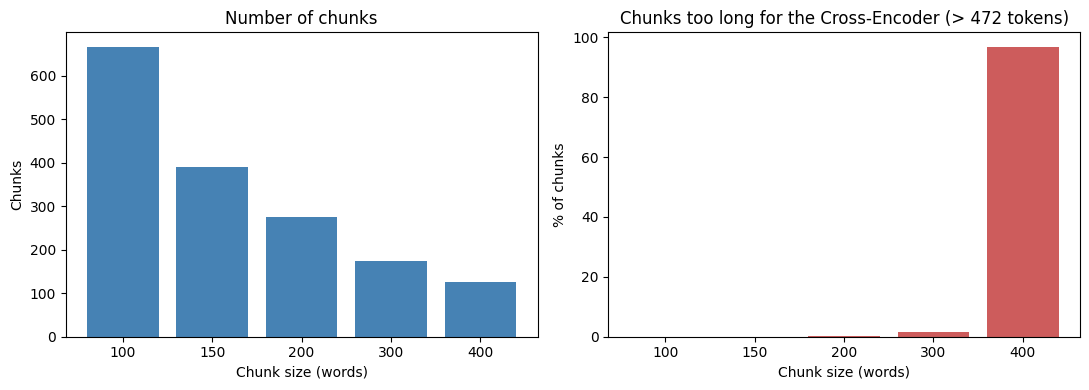

In [5]:
LIMIT = 512
def make_chunks(size, overlap=30):
    cs = [' '.join(words[i:i+size]) for i in range(0, len(words), size - overlap)]
    return [c for c in cs if len(c.split()) >= 50]   # drop tiny leftover at the end

rows = []
for size in [100, 150, 200, 300, 400]:
    cs = make_chunks(size)
    n_tok = np.array([len(tok(c, add_special_tokens=False, verbose=False)['input_ids']) for c in cs])
    rows.append({'chunk_words': size, 'n_chunks': len(cs), 'avg_tokens': n_tok.mean(),
                 'max_tokens': n_tok.max(), 'pct_too_long': 100 * (n_tok > LIMIT - 40).mean()})
exp = pd.DataFrame(rows)
print(exp.round(1).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(exp.chunk_words.astype(str), exp.n_chunks, color='steelblue')
ax[0].set(title='Number of chunks', xlabel='Chunk size (words)', ylabel='Chunks')
ax[1].bar(exp.chunk_words.astype(str), exp.pct_too_long, color='indianred')
ax[1].set(title='Chunks too long for the Cross-Encoder (> 472 tokens)', xlabel='Chunk size (words)', ylabel='% of chunks')
plt.tight_layout(); plt.show()

**Chosen:** 200 words, 30-word overlap. At 300 words some chunks already exceed the 512-token Cross-Encoder limit and at 400 almost all do, while 100 words splits rules into many small fragments (more than twice as many chunks). At 200 words the longest chunk is still below 512 tokens, leaving room for the query.

274 chunks | 200 words each, 30 words overlap
Tokens per chunk: min 218, mean 263, max 482 (limit 512)

--- C0 (200 words) ---
1 THE PLAYERS 1.1 Number of players A match is played between two sides, each of eleven players, one of whom shall be captain. 1.2 Nomination and replacement of players 1.2.1 Each captain shall nominate 11 players plus a maximum of 4 substitute fielders in writing on the team sheet provided by the ICC. Other than set out in clause 1.2.7, no player (member of the playing eleven) may be changed after the nomination and prior to the start of play without the consent of the opposing captain. Immedia ...

--- C137 (200 words) ---
on top of the stumps. – put back one or more stumps into the ground where the wicket originally stood. 29.5 Dispensing with bails If the umpires have agreed to dispense with bails in accordance with clause 8.4 (Dispensing with bails), it is for the umpire concerned to decide whether or not the wicket has been broken. 29.5.1 After a decision

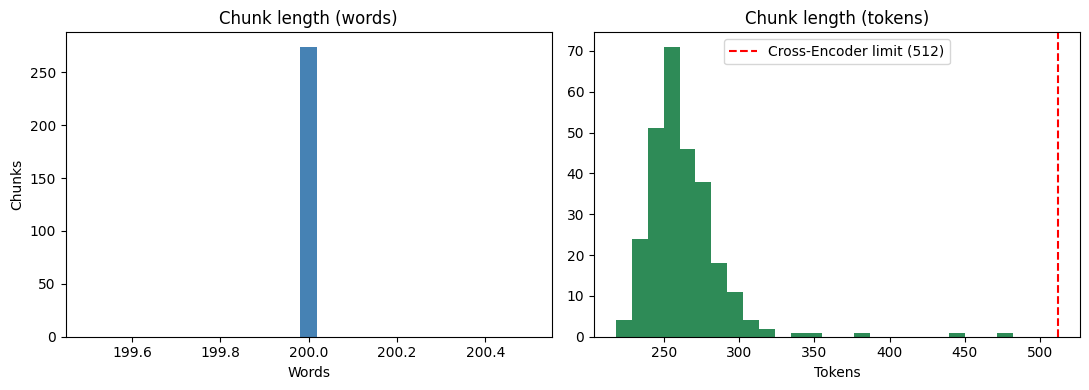

In [6]:
SIZE, OVERLAP = 200, 30
chunks = make_chunks(SIZE, OVERLAP)
ids = [f'C{i}' for i in range(len(chunks))]          # stable chunk ids used everywhere below
n_words = np.array([len(c.split()) for c in chunks])
n_tok = np.array([len(tok(c, add_special_tokens=False, verbose=False)['input_ids']) for c in chunks])
print(f'{len(chunks)} chunks | {SIZE} words each, {OVERLAP} words overlap')
print(f'Tokens per chunk: min {n_tok.min()}, mean {n_tok.mean():.0f}, max {n_tok.max()} (limit {LIMIT})\n')

for i in [0, len(chunks)//2, len(chunks)-1]:
    print(f'--- {ids[i]} ({n_words[i]} words) ---')
    print(chunks[i][:500], '...\n')

a, b = chunks[10].split()[-OVERLAP:], chunks[11].split()[:OVERLAP]
print('Overlap check (end of C10 == start of C11):', a == b)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(n_words, bins=25, color='steelblue'); ax[0].set(title='Chunk length (words)', xlabel='Words', ylabel='Chunks')
ax[1].hist(n_tok, bins=25, color='seagreen'); ax[1].axvline(LIMIT, color='red', ls='--', label='Cross-Encoder limit (512)')
ax[1].set(title='Chunk length (tokens)', xlabel='Tokens'); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Embed and index (Pipeline 1 foundation)
Vectors are L2-normalised, so inner product = cosine similarity.

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Embedding matrix: (274, 384) | vector norm: 1.0 | index size: 274


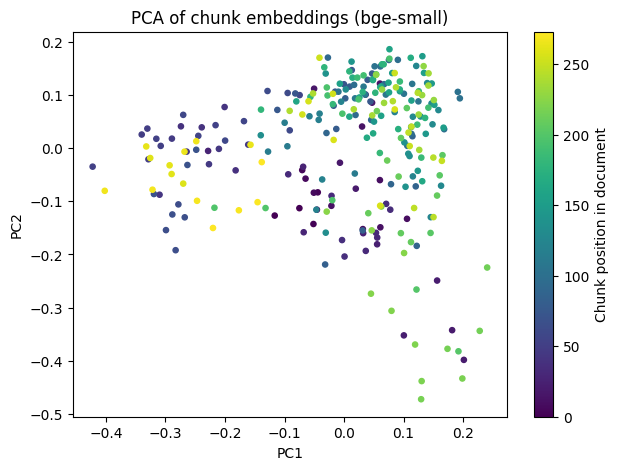

In [8]:
emb = bi.encode(chunks, normalize_embeddings=True, batch_size=32, show_progress_bar=True)
index = faiss.IndexFlatIP(emb.shape[1]); index.add(emb)
print('Embedding matrix:', emb.shape, '| vector norm:', round(float(np.linalg.norm(emb[0])), 3), '| index size:', index.ntotal)

from sklearn.decomposition import PCA
xy = PCA(2).fit_transform(emb)
plt.figure(figsize=(7, 5))
sc = plt.scatter(xy[:, 0], xy[:, 1], c=range(len(chunks)), cmap='viridis', s=14)
plt.colorbar(sc, label='Chunk position in document'); plt.title('PCA of chunk embeddings (bge-small)')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.show()

## 6. The two pipelines
Both pipelines use the same chunks, the same top-10 candidates and the same prompt. Only the choice of the 3 chunks sent to the LLM differs.

In [9]:
QP = 'Represent this sentence for searching relevant passages: '   # query prefix recommended for bge models

def retrieve(q, k=10):
    # Pipeline 1: embed query, inner-product search, return top-k chunk indices
    _, idx = index.search(bi.encode([QP + q], normalize_embeddings=True), k)
    return [int(i) for i in idx[0]]

def rerank(q, cand):
    # Pipeline 2: score all (query, chunk) pairs jointly, sort descending
    s = ce.predict([(q, chunks[i]) for i in cand])
    order = np.argsort(-s)
    return [cand[j] for j in order], [float(s[j]) for j in order]

def answer(q, cand):
    # identical prompt structure for Answer 1 and Answer 2
    ctx = '\n\n'.join(chunks[i] for i in cand)
    prompt = (f"Answer the question using only the context. If the answer is not in the context, say so. "
              f"Answer in at most 3 sentences.\n\nContext:\n{ctx}\n\nQuestion: {q}")
    return client.models.generate_content(model=MODEL, contents=prompt, config={'temperature': 0}).text

q = 'Who bats first in a Super Over?'
top10 = retrieve(q); rr, _ = rerank(q, top10)
print('Baseline top 10 :', [ids[i] for i in top10])
print('Reranked order  :', [ids[i] for i in rr])

Baseline top 10 : ['C264', 'C266', 'C265', 'C262', 'C267', 'C263', 'C268', 'C181', 'C117', 'C53']
Reranked order  : ['C264', 'C265', 'C266', 'C267', 'C262', 'C263', 'C53', 'C268', 'C117', 'C181']


## 6b. Failure mining with LLM-generated questions
Hand-written questions only test what I think of. To find failures systematically, the LLM writes one question for randomly chosen chunks (told to use everyday wording and synonyms, not the rulebook's phrases). For each question the *source chunk* is the gold chunk. We keep the questions where the baseline ranks it 4-10 and the Cross-Encoder lifts it into the top 3, and add up to 3 of them to the stress tests in section 7.

**Caveat:** an LLM-written question can occasionally also be answered by another chunk, so read the chunk printed for each one.

In [10]:
import random
random.seed(0)
N_MINE, MAX_FOUND, MAX_MINED = 60, 4, 3        # questions to try, stop after this many found, tests to keep
pool = [i for i in range(len(chunks)) if len(chunks[i].split()) >= 150]
sample = random.sample(pool, N_MINE)

def gen_question(text):
    prompt = ("Write ONE question that can be answered only from the passage below. Use everyday wording and "
              "synonyms; do not copy phrases from the passage; do not mention 'the passage' or clause numbers. "
              "Output only the question.\n\nPassage:\n" + text)
    for attempt in range(4):
        try:
            out = (client.models.generate_content(model=MODEL, contents=prompt, config={'temperature': 0.3}).text or '').strip()
            return out.split('\n')[0]
        except Exception as e:
            time.sleep(10 * (attempt + 1))
    return None

rows, n_found = [], 0
for i in sample:
    q = gen_question(chunks[i]); time.sleep(4)          # free-tier rate limit
    if not q or len(q) < 20: continue
    t10 = retrieve(q)
    b = t10.index(i) + 1 if i in t10 else None
    r = None
    if b is not None and b > 3:
        rr, _ = rerank(q, t10); r = rr.index(i) + 1
        if r <= 3: n_found += 1
    rows.append({'chunk': ids[i], 'query': q, 'baseline_rank': b, 'rerank_rank': r})
    if n_found >= MAX_FOUND and len(rows) >= 15: break
mined = pd.DataFrame(rows, columns=['chunk', 'query', 'baseline_rank', 'rerank_rank'])
print(f"Questions tried: {len(mined)} | source chunk in baseline top 3: {int((mined.baseline_rank <= 3).sum())} | "
      f"rank 4-10: {int((mined.baseline_rank > 3).sum())} | not in top 10: {int(mined.baseline_rank.isna().sum())}")

fixed_m = mined[(mined.baseline_rank > 3) & (mined.rerank_rank <= 3)].head(MAX_MINED)
mined_tests = [(m['query'], '@' + m.chunk, 'Other (LLM-generated)') for _, m in fixed_m.iterrows()]
print(f"\n{len(mined_tests)} generated question(s) kept as stress tests (baseline rank 4-10 -> re-ranked top 3):\n")
for _, m in fixed_m.iterrows():
    print(f"Q: {m['query']}\n   chunk {m.chunk}: baseline #{int(m.baseline_rank)} -> re-ranked #{int(m.rerank_rank)}")
    print('   CHUNK TEXT (verify it answers the question):', chunks[ids.index(m.chunk)][:700], '...\n')
if len(mined_tests) < 2: print('Fewer than 2 found: increase N_MINE (e.g. 120) and rerun this cell.')

Questions tried: 55 | source chunk in baseline top 3: 24 | rank 4-10: 7 | not in top 10: 24

3 generated question(s) kept as stress tests (baseline rank 4-10 -> re-ranked top 3):

Q: If a person filling in for an injured teammate breaks a serious rule, who is held responsible for the punishment?
   chunk C197: baseline #10 -> re-ranked #2
   CHUNK TEXT (verify it answers the question): umpires shall instruct the players to leave the field. The match is not concluded as in clause 16.2 and there shall be no result under clause 16. 42.4 Additional points relating to Level 4 offences 42.4.1 If a player, while acting as wicket-keeper, commits a Level 4 offence, clause 24.1.2 shall not apply, meaning that only a nominated player may keep wicket, even if another fielder becomes injured or ill and is replaced by a substitute. 42.4.2 A nominated player who has a substitute will also suffer the penalty for any Level 4 offence committed by the substitute. However, only the substitute will be repo

## 7. Stress-test screening (no LLM calls)
Each test is `(query, gold phrase, intended category)`; the last tests come from section 6b and use `@C<id>` (the source chunk) instead of a phrase. The **gold phrase** is a short phrase copied from the clause that actually answers the query (I picked it by reading the rulebook); a chunk containing it is the *gold chunk*. We record the gold chunk's rank before and after re-ranking.

Status meaning: **FIXED BY RERANK** = gold at rank 4–10 in the baseline, in the top 3 after re-ranking · **ALREADY OK** = in the top 3 both times · **WORSENED** = top 3 before, not after · **STILL MISSED** = in the top 10 but never in the top 3 · **NOT IN TOP 10** = the Bi-Encoder never retrieved it, so the Cross-Encoder cannot help (it only re-orders the 10 candidates) · **GOLD NOT FOUND** = phrase not in any chunk (fix the phrase).

*The category column is the intended failure type. Judge the real type from the outcome and the chunks shown in sections 8 and 9.*

  Q                                                                                                             query                 category  gold_chunks  baseline_rank  rerank_rank          status
 Q1                                                                  How many bouncers can a bowler bowl in one over?             Keyword trap       [C172]            NaN          NaN   NOT IN TOP 10
 Q2                                           How many times can a team challenge an umpire's decision in an innings?             Keyword trap       [C252]            NaN          NaN   NOT IN TOP 10
 Q3                                         How long does a new batter have to reach the crease after a wicket falls?             Keyword trap       [C161]            1.0          1.0      ALREADY OK
 Q4                                                      How long is the break between the two overs of a Super Over?             Keyword trap       [C265]            2.0          1.0      ALREADY OK


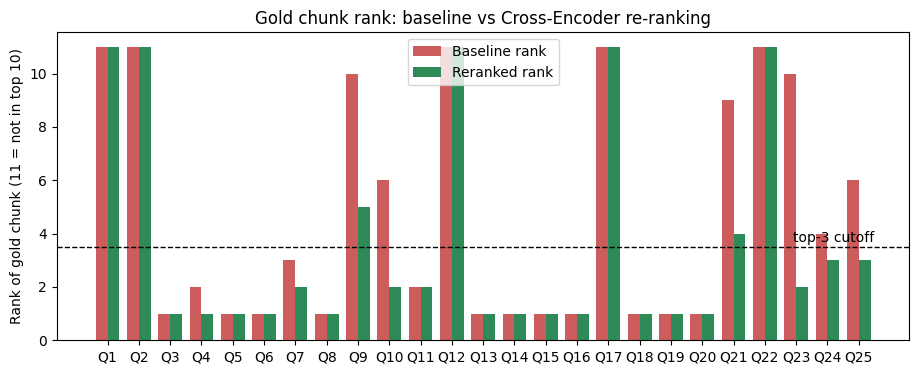

In [11]:
hand_written = [
    # Keyword trap / synonym gap: query wording differs from the rule's wording
    ("How many bouncers can a bowler bowl in one over?", "limited to one fast short-pitched delivery per over", "Keyword trap"),
    ("How many times can a team challenge an umpire's decision in an innings?", "maximum of two player review requests", "Keyword trap"),
    ("How long does a new batter have to reach the crease after a wicket falls?", "within 1 minute 30 seconds", "Keyword trap"),
    ("How long is the break between the two overs of a Super Over?", "interval between the two overs in the super over", "Keyword trap"),
    ("Who picks the ball for the Super Over?", "shall select the ball", "Keyword trap"),
    ("How many fielders may be outside the circle in the Powerplay?", "only two fielders shall be permitted outside", "Keyword trap"),
    # Exceptions & corner cases: general rule vs the exception elsewhere
    ("What is the maximum number of overs one bowler can bowl in a T20 innings?", "no bowler shall bowl more than 4 overs", "Exception (general rule)"),
    ("How many overs can a bowler bowl if the innings is cut down to 8 overs?", "no bowler may bowl more than two overs", "Exception"),
    ("What happens on the ball after a No ball is bowled?", "shall be a free hit for whichever batter", "Exception"),
    ("Can a batter be bowled when the umpire has called a Wide?", "neither batter shall be out under any", "Exception / negation"),
    ("Is it illegal fielding if the ball hits a cap that fell accidentally off a fielder?", "it is not illegal fielding", "Exception / negation"),
    # Negation & constraints
    ("Can a batter be out LBW off a No ball?", "the bowler delivers a ball, not being a no ball", "Negation"),
    ("Can a bowler who bowled in the previous Super Over bowl again?", "ineligible to bowl", "Negation"),
    ("Can a batter dismissed in an earlier Super Over bat again?", "ineligible to bat", "Negation"),
    # Other
    ("Who bats first in a Super Over?", "shall bat first in the super over", "Other"),
    ("How many substitute fielders can a captain nominate?", "maximum of 4 substitute fielders", "Other"),
    ("How quickly must the fielding side be ready to bowl the next over?", "start each over within 60 seconds", "Other"),
    # Role limits, exceptions and synonym gaps
    ("Can a bowler bowl two overs in a row if he switches ends?", "provided he does not bowl two overs consecutively", "Negation"),
    ("Can a substitute fielder keep wicket?", "may act as wicket-keeper only with the consent of the umpires", "Exception"),
    ("Can a substitute fielder bowl or captain the side?", "a substitute shall not bowl or act as captain", "Negation (role limit)"),
    ("Can a batter be bowled if the ball touched a fielder before hitting the stumps?", "the striker shall not be out bowled if before striking the wicket", "Exception / negation"),
    ("What happens if the bowler switches to round the wicket without telling the umpire?", "it is unfair if the bowler fails to notify the umpire of a change in his mode of delivery", "Keyword trap"),
]
candidates = hand_written + mined_tests          # mined_tests comes from section 6b

def norm(s):   # lowercase, collapse whitespace, join words broken by line-end hyphens
    return ' '.join(s.lower().split()).replace('- ', '-')
chunks_norm = [norm(c) for c in chunks]

def best_rank(order, hits):
    r = [order.index(h) + 1 for h in hits if h in order]
    return min(r) if r else None

store, rows = {}, []
for n, (q, gold, cat) in enumerate(candidates):
    hits = [int(gold[2:])] if gold.startswith('@C') else [i for i, c in enumerate(chunks_norm) if norm(gold) in c]
    t10 = retrieve(q); rr, sc_ = rerank(q, t10)
    store[n] = {'t10': t10, 'rr': rr, 'scores': sc_, 'hits': hits}
    b, r = best_rank(t10, hits), best_rank(rr, hits)
    if not hits: status = 'GOLD NOT FOUND'
    elif b is None: status = 'NOT IN TOP 10'
    elif b <= 3 and r <= 3: status = 'ALREADY OK'
    elif b > 3 and r <= 3: status = 'FIXED BY RERANK'
    elif b <= 3 and r > 3: status = 'WORSENED'
    else: status = 'STILL MISSED'
    rows.append({'Q': f'Q{n+1}', 'query': q, 'category': cat, 'gold_chunks': [ids[h] for h in hits],
                 'baseline_rank': b, 'rerank_rank': r, 'status': status})
res = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 75, 'display.width', 250)
print(res.to_string(index=False))
print('\n', res.status.value_counts().to_string())

x = np.arange(len(res)); w = 0.38
bb = res.baseline_rank.fillna(11).values; rb = res.rerank_rank.fillna(11).values
plt.figure(figsize=(11, 4))
plt.bar(x - w/2, bb, w, label='Baseline rank', color='indianred'); plt.bar(x + w/2, rb, w, label='Reranked rank', color='seagreen')
plt.axhline(3.5, color='k', ls='--', lw=1); plt.text(len(res) - 0.5, 3.7, 'top-3 cutoff', ha='right')
plt.xticks(x, res.Q); plt.ylabel('Rank of gold chunk (11 = not in top 10)')
plt.title('Gold chunk rank: baseline vs Cross-Encoder re-ranking'); plt.legend(); plt.show()

## 8. Answer 1 vs Answer 2 for every stress test
For each query the LLM answers twice with the identical prompt: once with the baseline top 3 (Answer 1) and once with the re-ranked top 3 (Answer 2). If both pipelines pick exactly the same 3 chunks in the same order the prompts are identical, so the answer is reused instead of calling the API again.

Q1 [Keyword trap] How many bouncers can a bowler bowl in one over?
Gold ['C172']: baseline rank nan -> reranked nan  |  status: NOT IN TOP 10
Baseline top 3: ['C55', 'C71', 'C266']  gold in context: NO
Reranked top 3: ['C55', 'C74', 'C73']  gold in context: NO

ANSWER 1 (baseline): The provided context does not contain information regarding the number of bouncers a bowler can bowl in one over.
ANSWER 2 (re-ranked): The provided context does not contain information regarding the number of bouncers a bowler can bowl in one over.
>>> different context, same answer
Q2 [Keyword trap] How many times can a team challenge an umpire's decision in an innings?
Gold ['C252']: baseline rank nan -> reranked nan  |  status: NOT IN TOP 10
Baseline top 3: ['C228', 'C239', 'C264']  gold in context: NO
Reranked top 3: ['C264', 'C196', 'C113']  gold in context: NO

ANSWER 1 (baseline): Each team is allowed one unsuccessful player review per innings per Super Over. The provided context does not specify the

,Q,category,status,gold_in_ctx_base,gold_in_ctx_rerank,same_context,answers_differ
0,Q1,Keyword trap,NOT IN TOP 10,False,False,False,False
1,Q2,Keyword trap,NOT IN TOP 10,False,False,False,True
2,Q3,Keyword trap,ALREADY OK,True,True,False,False
3,Q4,Keyword trap,ALREADY OK,True,True,False,False
4,Q5,Keyword trap,ALREADY OK,True,True,False,False
5,Q6,Keyword trap,ALREADY OK,True,True,False,False
6,Q7,Exception (general rule),ALREADY OK,True,True,False,True
7,Q8,Exception,ALREADY OK,True,True,False,True
8,Q9,Exception,STILL MISSED,False,False,False,False
9,Q10,Exception / negation,FIXED BY RERANK,False,True,False,True


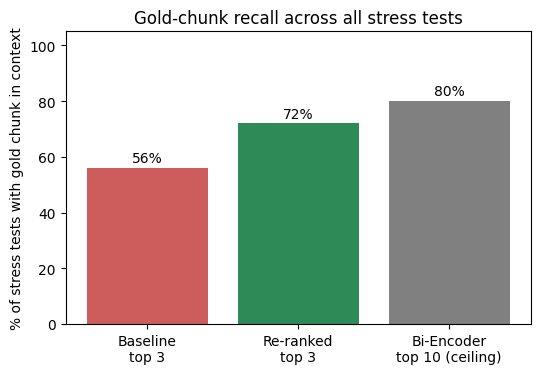

In [12]:
cache = {}
def ask(q, cand):
    key = (q, tuple(cand))
    if key not in cache:
        out = 'ERROR'
        for attempt in range(4):
            try:
                out = answer(q, cand) or 'EMPTY RESPONSE'; break
            except Exception as e:
                print('   retrying after error:', str(e)[:80]); time.sleep(10 * (attempt + 1))
        cache[key] = out; time.sleep(4)          # stay under the free-tier rate limit
    return cache[key]

rows = []
for n, (q, gold, cat) in enumerate(candidates):
    s = store[n]; hits = set(s['hits'])
    c1, c2 = s['t10'][:3], s['rr'][:3]
    a1, a2 = ask(q, c1), ask(q, c2)
    g1, g2 = bool(hits & set(c1)), bool(hits & set(c2))
    same_ctx = c1 == c2
    r = res.iloc[n]
    print('=' * 100)
    print(f"Q{n+1} [{cat}] {q}")
    print(f"Gold {r.gold_chunks}: baseline rank {r.baseline_rank} -> reranked {r.rerank_rank}  |  status: {r.status}")
    print(f"Baseline top 3: {[ids[i] for i in c1]}  gold in context: {'YES' if g1 else 'NO'}")
    print(f"Reranked top 3: {[ids[i] for i in c2]}  gold in context: {'YES' if g2 else 'NO'}")
    print(f"\nANSWER 1 (baseline): {a1.strip()}")
    print(f"ANSWER 2 (re-ranked): {a2.strip()}")
    print('>>> same context' if same_ctx else ('>>> answers DIFFER' if a1.strip() != a2.strip() else '>>> different context, same answer'))
    rows.append({'Q': f'Q{n+1}', 'category': cat, 'status': r.status, 'gold_in_ctx_base': g1, 'gold_in_ctx_rerank': g2,
                 'same_context': same_ctx, 'answers_differ': a1.strip() != a2.strip(), 'answer_1': a1.strip(), 'answer_2': a2.strip()})
cmp = pd.DataFrame(rows)

print('\n\nSUMMARY')
display(cmp[['Q', 'category', 'status', 'gold_in_ctx_base', 'gold_in_ctx_rerank', 'same_context', 'answers_differ']])

valid = res.status != 'GOLD NOT FOUND'
r3b = cmp.gold_in_ctx_base[valid.values].mean() * 100
r3r = cmp.gold_in_ctx_rerank[valid.values].mean() * 100
r10 = np.mean([bool(set(store[n]['hits']) & set(store[n]['t10'])) for n in range(len(candidates)) if valid.iloc[n]]) * 100
plt.figure(figsize=(6, 3.8))
plt.bar(['Baseline\ntop 3', 'Re-ranked\ntop 3', 'Bi-Encoder\ntop 10 (ceiling)'], [r3b, r3r, r10], color=['indianred', 'seagreen', 'gray'])
plt.ylabel('% of stress tests with gold chunk in context'); plt.ylim(0, 105)
for i, v in enumerate([r3b, r3r, r10]): plt.text(i, v + 2, f'{v:.0f}%', ha='center')
plt.title('Gold-chunk recall across all stress tests'); plt.show()

## 9. Rank-shift detail
For every FIXED or WORSENED query: where each of the 10 candidates sat before and after re-ranking, with the Cross-Encoder score. The baseline's top-ranked chunk is the *distractor* that outranked the gold chunk.

In [13]:
show = res[res.status.isin(['FIXED BY RERANK', 'WORSENED'])]
if show.empty: print('No FIXED or WORSENED queries to show.')
for _, r in show.iterrows():
    n = int(r.Q[1:]) - 1; s = store[n]; hits = set(s['hits'])
    print('=' * 100); print(f"{r.Q} [{r.category}] {r.query}  ->  {r.status}")
    tab = pd.DataFrame({'rank_after': range(1, 11), 'chunk': [ids[i] for i in s['rr']],
                        'rank_before': [s['t10'].index(i) + 1 for i in s['rr']],
                        'ce_score': np.round(s['scores'], 2), 'is_gold': ['GOLD' if i in hits else '' for i in s['rr']]})
    print(tab.to_string(index=False))
    print(f"\nBaseline #1 chunk ({ids[s['t10'][0]]}), the distractor:\n  {chunks[s['t10'][0]][:350]} ...")
    g = [i for i in s['t10'] if i in hits][0]
    print(f"\nGold chunk ({ids[g]}):\n  {chunks[g][:350]} ...")

Q10 [Exception / negation] Can a batter be bowled when the umpire has called a Wide?  ->  FIXED BY RERANK
 rank_after chunk  rank_before  ce_score is_gold
          1  C107            1      6.01        
          2  C109            6      5.24    GOLD
          3  C108            4      4.95        
          4  C172            3      4.61        
          5  C106            2      4.17        
          6   C72           10      3.94        
          7  C132            5      2.69        
          8  C131            8      0.87        
          9  C186            7      0.28        
         10  C228            9     -2.16        

Baseline #1 chunk (C107), the distractor:
  consistent interpretation in regard to this clause in order to prevent negative bowling wide of the wicket. 22.2 Call and signal of Wide ball If the umpire adjudges a delivery to be a Wide he/she shall call and signal Wide ball as soon as the ball passes the striker’s wicket. It shall, however, be considered 

## 10. Latency profiling
Timed over 5 different queries (retrieval: 5 runs each, re-ranking: 3 runs each, after one warm-up run), and the LLM over 3 queries. Same machine and same inputs for both pipelines.

Device: CPU
                                              Stage  Mean time (ms)
Pipeline 1: retrieval (embed query + top-10 search)            55.7
                    Re-ranking step only (10 pairs)          2111.8
                 Pipeline 2: retrieval + re-ranking          2167.4
                            LLM generation (1 call)          1350.7

Pipeline 2 retrieval is 38.9x slower than Pipeline 1 retrieval
Cross-Encoder cost per (query, chunk) pair: 211.18 ms
Cross-Encoder over all 274 chunks: 57862 ms per query


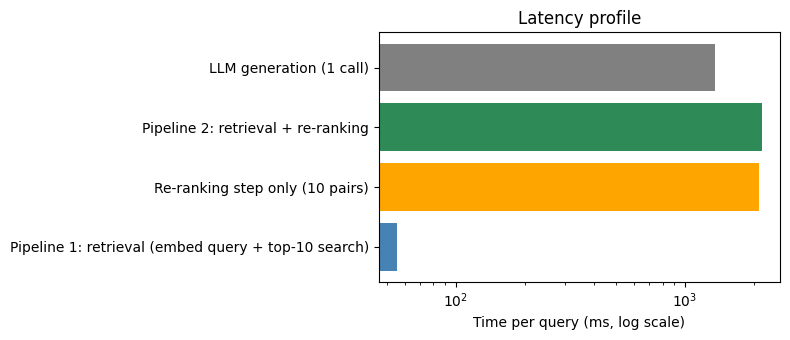

In [14]:
def timed(f, n):
    f(); ts = []                       # warm-up run, then n timed runs
    for _ in range(n):
        t = time.perf_counter(); f(); ts.append((time.perf_counter() - t) * 1000)
    return np.mean(ts)

qs = [c[0] for c in candidates[:5]]
base_t, rr_t = [], []
for q in qs:
    t10 = retrieve(q)
    base_t.append(timed(lambda: retrieve(q), 5))
    rr_t.append(timed(lambda: rerank(q, t10), 3))
llm_t = []
for q in qs[:3]:
    t10 = retrieve(q); t0 = time.perf_counter(); answer(q, t10[:3]); llm_t.append((time.perf_counter() - t0) * 1000); time.sleep(1.5)

t_base, t_rr, t_llm = np.mean(base_t), np.mean(rr_t), np.mean(llm_t)
t_pair = t_rr / 10
lat = pd.DataFrame({'Stage': ['Pipeline 1: retrieval (embed query + top-10 search)', 'Re-ranking step only (10 pairs)',
                              'Pipeline 2: retrieval + re-ranking', 'LLM generation (1 call)'],
                    'Mean time (ms)': [t_base, t_rr, t_base + t_rr, t_llm]})
print('Device:', 'GPU' if torch.cuda.is_available() else 'CPU')
print(lat.round(1).to_string(index=False))
print(f'\nPipeline 2 retrieval is {(t_base + t_rr) / t_base:.1f}x slower than Pipeline 1 retrieval')
print(f'Cross-Encoder cost per (query, chunk) pair: {t_pair:.2f} ms')
print(f'Cross-Encoder over all {len(chunks)} chunks: {t_pair * len(chunks):.0f} ms per query')

plt.figure(figsize=(8, 3.5))
plt.barh(lat.Stage, lat['Mean time (ms)'], color=['steelblue', 'orange', 'seagreen', 'gray']); plt.xscale('log')
plt.xlabel('Time per query (ms, log scale)'); plt.title('Latency profile'); plt.tight_layout(); plt.show()

## 11. Scaling: why not run the Cross-Encoder on everything?
Measured cost per pair (above) extrapolated to larger corpora. The Cross-Encoder must run a full forward pass for every (query, chunk) pair and nothing can be precomputed, because the score depends on the query. Bi-Encoder chunk vectors are computed once; a query then needs one embedding plus a vector search (approximate-nearest-neighbour indexes keep this nearly flat).

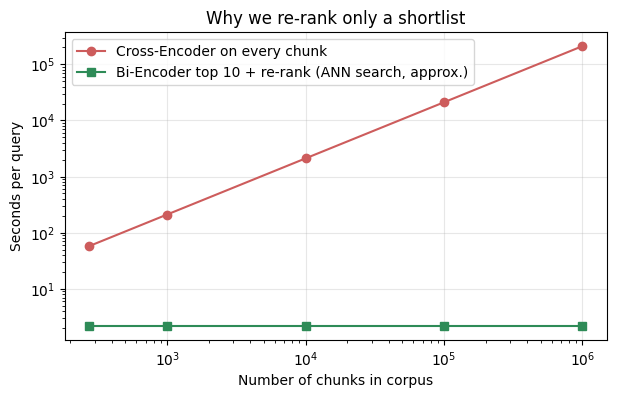

      274 chunks: Cross-Encoder only =       57.9 s per query
    1,000 chunks: Cross-Encoder only =      211.2 s per query
   10,000 chunks: Cross-Encoder only =    2,111.8 s per query
  100,000 chunks: Cross-Encoder only =   21,117.6 s per query
1,000,000 chunks: Cross-Encoder only =  211,175.6 s per query


In [15]:
N = np.array([len(chunks), 1e3, 1e4, 1e5, 1e6])
plt.figure(figsize=(7, 4))
plt.loglog(N, t_pair * N / 1000, 'o-', color='indianred', label='Cross-Encoder on every chunk')
plt.loglog(N, np.full(len(N), (t_base + t_rr) / 1000), 's-', color='seagreen', label='Bi-Encoder top 10 + re-rank (ANN search, approx.)')
plt.xlabel('Number of chunks in corpus'); plt.ylabel('Seconds per query'); plt.title('Why we re-rank only a shortlist')
plt.legend(); plt.grid(alpha=.3); plt.show()
for n_ in N: print(f'{int(n_):>9,} chunks: Cross-Encoder only = {t_pair * n_ / 1000:>10,.1f} s per query')